## The lab was fulfilled by Pozhylenkov Andrew (group K-10)
<b>Variant 20</b>

In [274]:
import sys
import matplotlib
import matplotlib.pyplot as plt
import pandas as pd

Versions:

In [275]:
print(f'Matplotlib version: {matplotlib.__version__}')
print(f'Pandas version: {pd.__version__}')
print(f'Python vesion: {sys.version}')

Matplotlib version: 3.8.4
Pandas version: 2.2.2
Python vesion: 3.11.9 (main, Apr  2 2024, 08:25:04) [Clang 15.0.0 (clang-1500.3.9.4)]


Period:

In [276]:
P = 20 % 12 + 1
P

9

Creating DataFrame

In [277]:
data = pd.read_csv('weather.csv')

### 1. Для періоду P побудувати лінійні графіки зміни денної температури, нічної температури, хмарності та сили вітру по днях. Графіки укласти на один рисунок (але не в один графік)

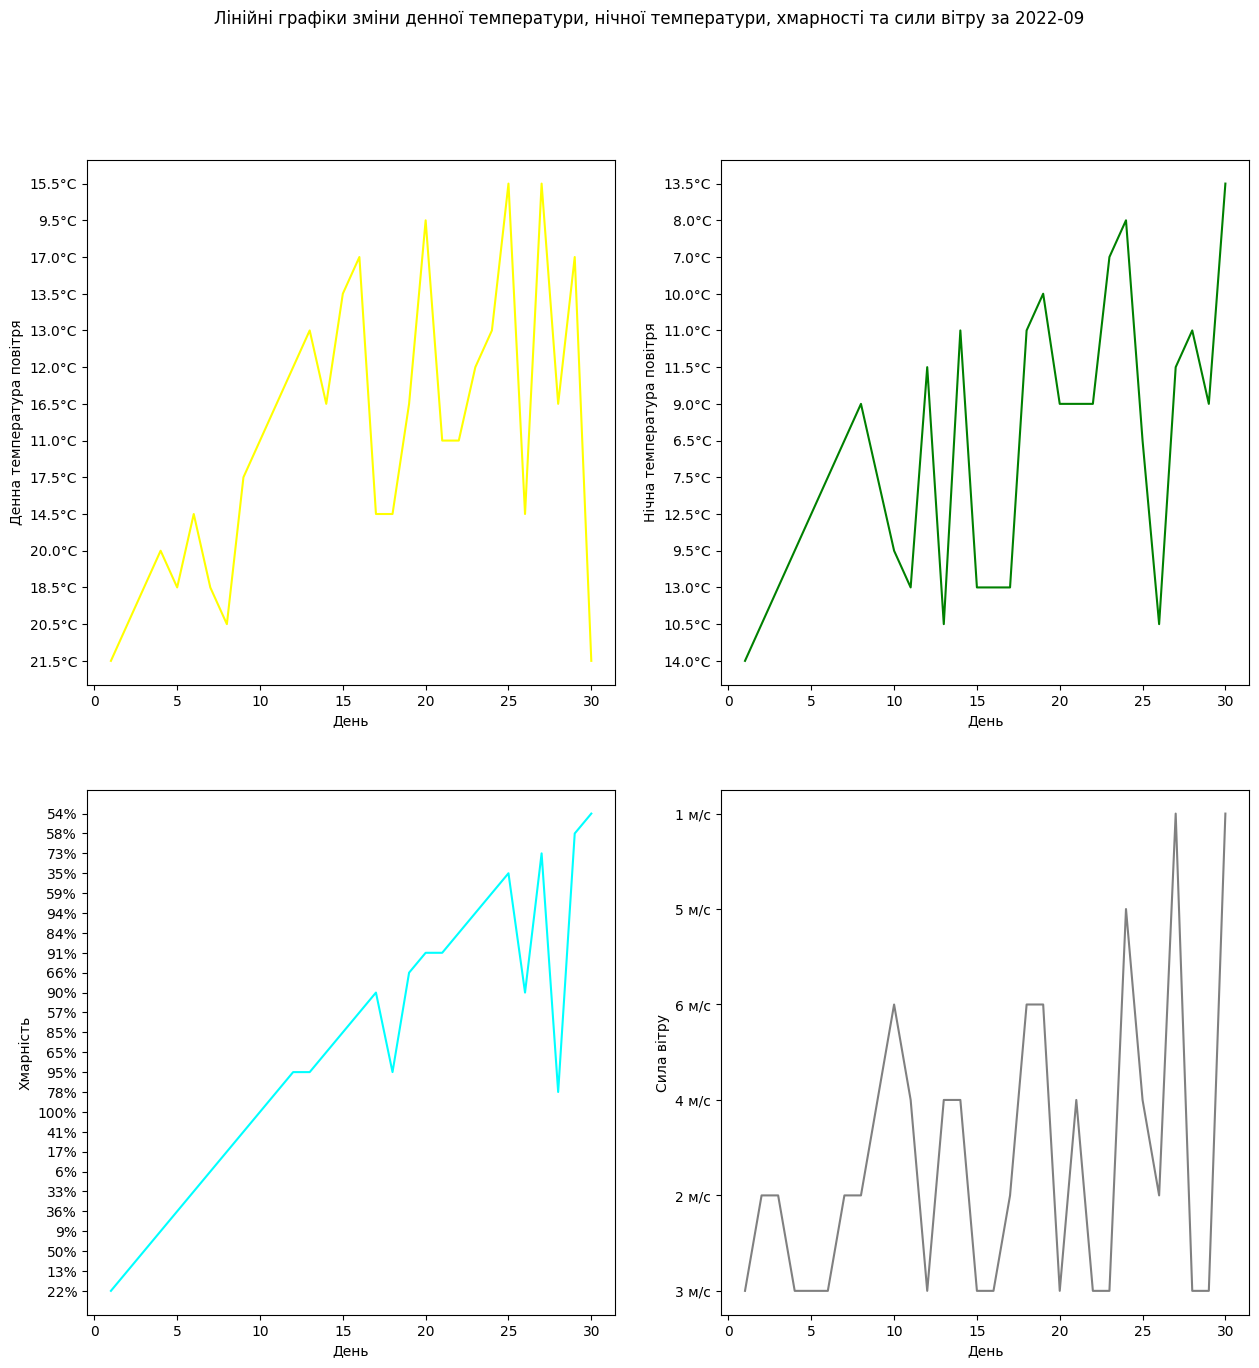

In [278]:
period_part = data[data['період'].str.match(r'20\d{2}-09')]

figure = plt.figure(figsize=(15, 15))
figure.suptitle('Лінійні графіки зміни денної температури, нічної температури, хмарності та сили вітру за 2022-09')

graphic1 = figure.add_subplot(2, 2, 1)
graphic1.plot(period_part['день'], period_part['денна температура повітря'], color='yellow')
graphic1.set_xlabel('День')
graphic1.set_ylabel('Денна температура повітря')

graphic2 = figure.add_subplot(2, 2, 2)
graphic2.plot(period_part['день'], period_part['нічна температура повітря'], color='green')
graphic2.set_xlabel('День')
graphic2.set_ylabel('Нічна температура повітря')

graphic3 = figure.add_subplot(2, 2, 3)
graphic3.plot(period_part['день'], period_part['хмарність'], color='aqua')
graphic3.set_xlabel('День')
graphic3.set_ylabel('Хмарність')

graphic4 = figure.add_subplot(2, 2, 4)
graphic4.plot(period_part['день'], period_part['сила вітру'], color='grey')
graphic4.set_xlabel('День')
graphic4.set_ylabel('Сила вітру')

plt.show()

### 2. Для періоду P побудувати бульбашковий (scatter) графік денної температури, діаметр “бульбашки” має залежати від кількості опадів. Якщо опадів не було, то підібрати якесь невелике значення, щоб була просто помітна точка.

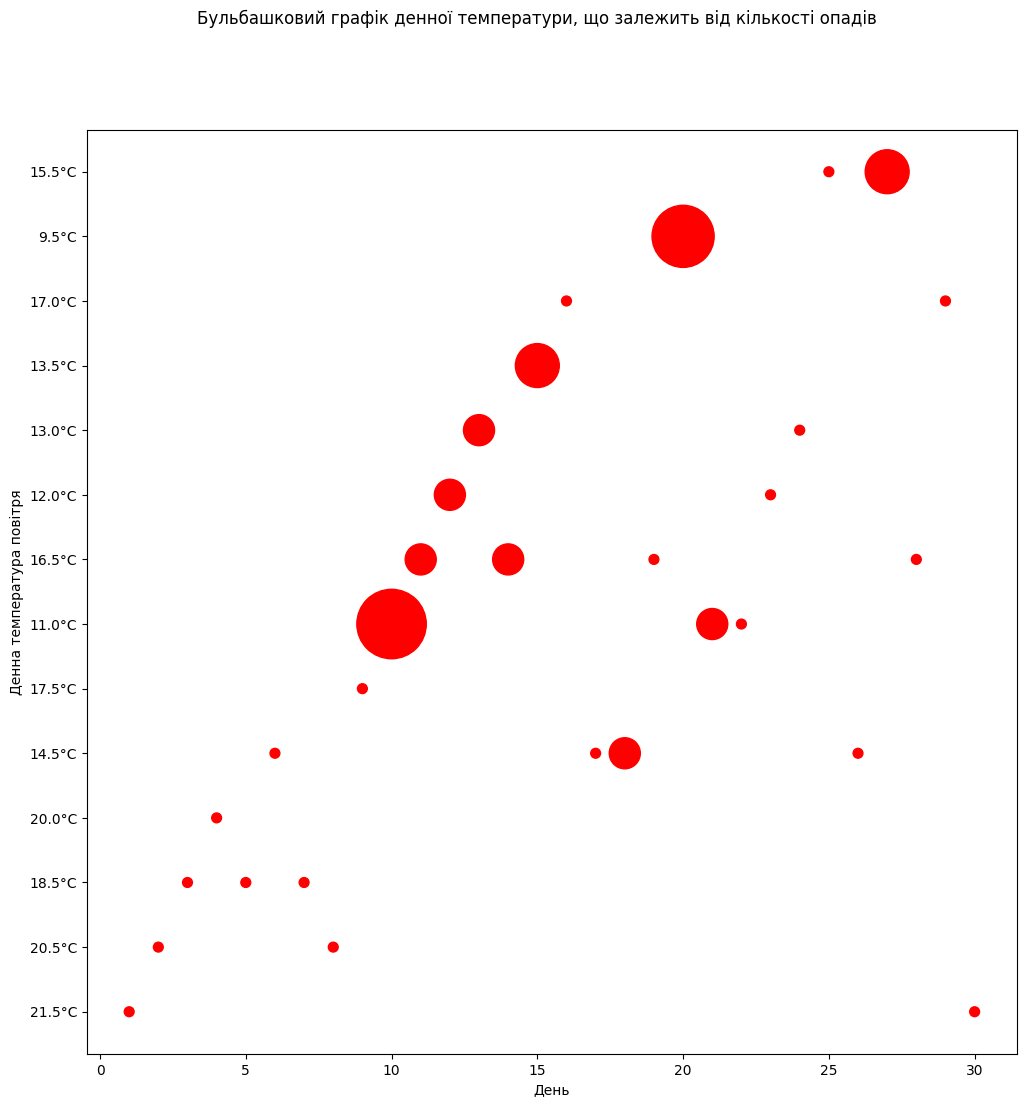

In [279]:
period_opadu_df = period_part['опади'].replace('-', '0.1 м.м.')
period_opadu_df = period_opadu_df.str.findall(r'(\d+.*\d*) м.м.').str[0]
period_opadu_df = period_opadu_df.astype(float)

figure = plt.figure(figsize=(12,12))
figure.suptitle('Бульбашковий графік денної температури, що залежить від кількості опадів')
plt.xlabel('День')
plt.ylabel('Денна температура повітря')
plt.scatter(period_part['день'], period_part['денна температура повітря'], s=period_opadu_df*500, color='red')
plt.show()

### 3. Знайти середнє по місяцях відхилення нічної температури від денної.

In [280]:
data_copy = data.copy()

patt = r'-*\d+.\d+'

data_day_temperature = data['денна температура повітря'].str.findall(patt).str[0].astype(float)
data_night_temperature = data['нічна температура повітря'].str.findall(patt).str[0].astype(float)

data_copy['Відхилення'] = abs(data_day_temperature - data_night_temperature)

result = data_copy.groupby('період').agg({'Відхилення':'mean'})
result

,Відхилення
період,
2022-05,7.451613
2022-06,8.316667
2022-07,8.693548
2022-08,9.467742
2022-09,5.416667
2022-10,5.177419
2022-11,3.200000
2022-12,2.725806
2023-01,2.887097


### 4. Знайти всі дні, коли фіксувалась найбільша розбіжність між денною та нічною температурами, та вивести для них усю наявну інформацію.

In [281]:
result = data_copy.nlargest(n=1, columns='Відхилення', keep='all')
result['Відхилення'] = result['Відхилення'].astype(str)
result['Відхилення'] = result['Відхилення'] + '°C'
result

,день,хмарність,опади,денна температура повітря,нічна температура повітря,сила вітру,період,Відхилення
267,26,9%,-,36.5°C,20.5°C,4 м/с,2022-08,16.0°C


### 5. У періоді P знайти 4 найбільш вітрених дні та вивести для них усю наявну інформацію.

In [282]:
period_part = data[data['період'].str.match(r'20\d{2}-09')]

series_of_winds = period_part['сила вітру'].str.findall(r'(\d)+ \w/\w+')

period_part.loc[:, 'сила вітру'] = series_of_winds.str[0]
period_part['сила вітру'] = period_part['сила вітру'].astype('int64')

result = period_part.nlargest(n=4, columns='сила вітру', keep='all').astype('object')

result.loc[:, 'сила вітру'] = series_of_winds.str[0] + ' м/c'
result

/var/folders/ml/xkvgsfsd6px2j4560wfj3g_r0000gn/T/ipykernel_75134/2944811939.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  period_part['сила вітру'] = period_part['сила вітру'].astype('int64')


,день,хмарність,опади,денна температура повітря,нічна температура повітря,сила вітру,період
221,10,100%,5 м.м.,11.0°C,9.5°C,6 м/c,2022-09
229,18,95%,1 м.м.,14.5°C,11.0°C,6 м/c,2022-09
230,19,66%,-,16.5°C,10.0°C,6 м/c,2022-09
235,24,59%,-,13.0°C,8.0°C,5 м/c,2022-09


### 6. Знайти скільки в кожному місяці було днів з опадами. Побудувати кругову діаграму.

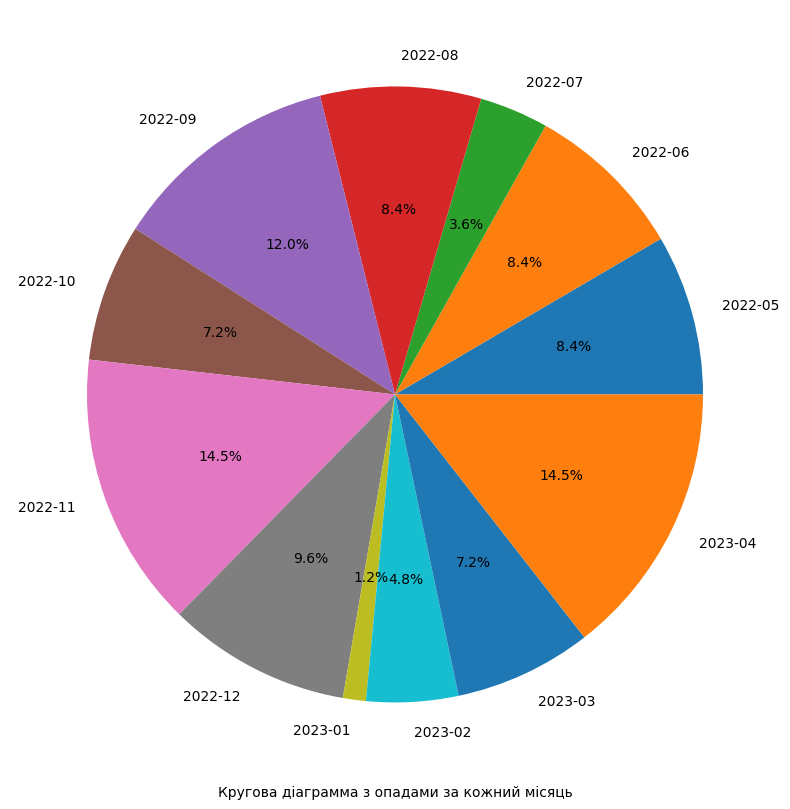

In [283]:
data_copy = data.copy()
data_copy.replace('-', pd.NA, inplace=True)
data_copy.dropna(inplace=True)

opadu_df = pd.DataFrame({'Опади':data_copy['опади'], 'Місяць':data_copy['період']})
opadu_df = opadu_df.groupby('Місяць').count()
result = opadu_df
result
result['Опади'].plot.pie(figsize=(10, 10), autopct='%1.1f%%')
plt.ylabel('')
plt.xlabel('Кругова діаграмма з опадами за кожний місяць')
plt.show()

### 7. Якщо хмарність більша 70%, то вважатимемо день хмарним. Якщо хмарність менша 35%, вважатимемо день сонячним. У решті випадків вважаємо, що в той день була мінлива хмарність. Знайти кількість днів кожного типу на місяць та побудувати стовпчикову діаграму з накопиченням.

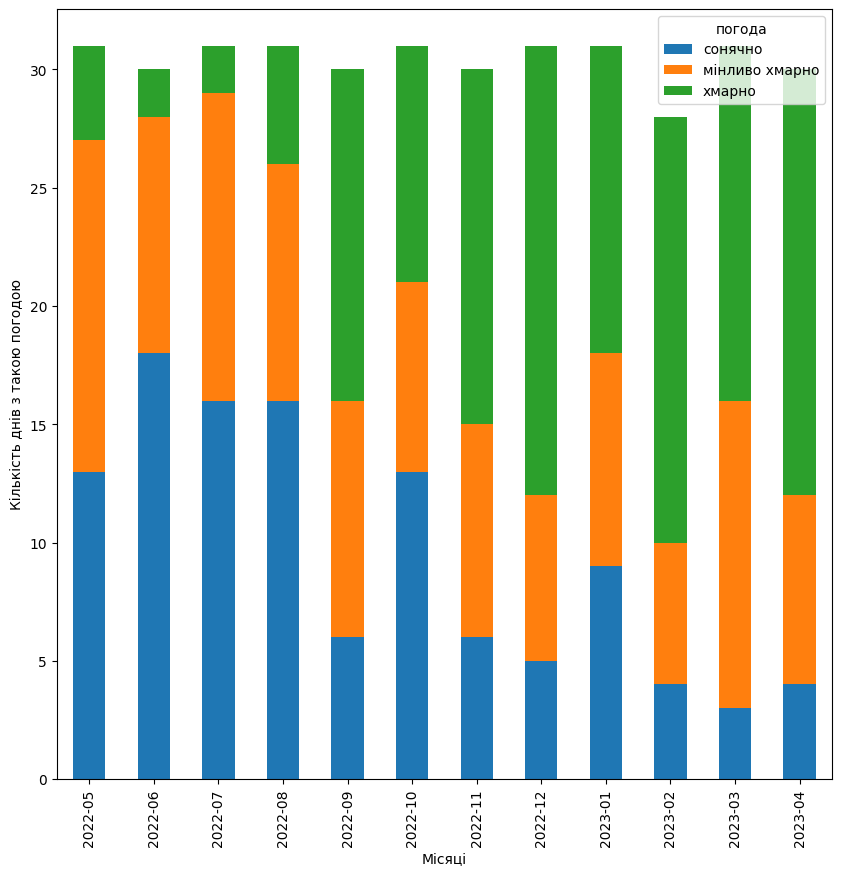

In [284]:
data_copy = data.copy()
data_copy.rename(columns={'період':'Місяць'}, inplace=True)
data_copy['хмарність'] = data_copy['хмарність'].str.findall(r'(\d+)%').str[0].astype(int)

bins = [-1, 34, 69, 100]
data_copy['погода'] = pd.cut(data_copy['хмарність'], bins, labels=['сонячно', 'мінливо хмарно', 'хмарно'])

data_pivot = data_copy.pivot(index=['Місяць', 'день'], columns='погода', values='погода')
cloudness_df = data_pivot.groupby('Місяць').count()
result = cloudness_df

result.plot.bar(stacked=True, figsize=(10,10), legend=True)
plt.xlabel('Місяці')
plt.ylabel('Кількість днів з такою погодою')
plt.show()

### 8. Знайти всі місяці, в яких сонячних днів було більше, ніж днів з опадами.

In [285]:
data_copy = cloudness_df.copy()

sunny_and_opadu_df = pd.DataFrame({'Сонячно': data_copy['сонячно'], 'Опади': opadu_df['Опади']})
sunny_and_opadu_df[sunny_and_opadu_df['Сонячно'] > sunny_and_opadu_df['Опади']]

,Сонячно,Опади
Місяць,,
2022-05,13,7
2022-06,18,7
2022-07,16,3
2022-08,16,7
2022-10,13,6
2023-01,9,1


### 9. Побудувати гістограму відхилення нічної температури від денної.

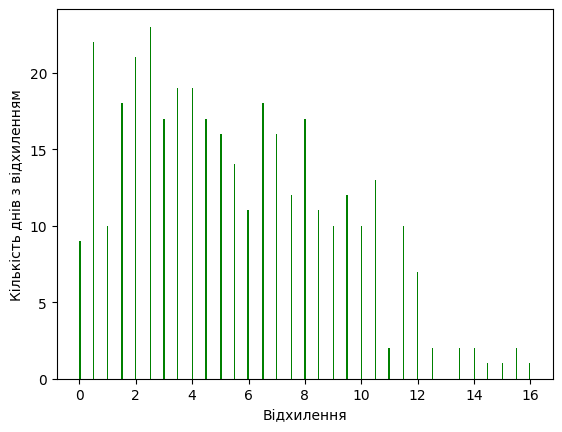

In [286]:
data_copy = data.copy()

pattt = r'-*\d+.\d+'

data_day_temperature = data['денна температура повітря'].str.findall(patt).str[0].astype(float)
data_night_temperature = data['нічна температура повітря'].str.findall(patt).str[0].astype(float)

data_copy['відхилення'] = abs(data_day_temperature - data_night_temperature)

new_df = pd.DataFrame({'день':data_copy['день'], 'відхилення': data_copy['відхилення']})
new_df.set_index(new_df['день'], inplace=True)
new_df.drop(columns=['день'], inplace=True)
new_df.plot.hist(color='green', legend=False, bins=len(new_df))

plt.xlabel('Відхилення')
plt.ylabel('Кількість днів з відхиленням')
plt.show()